In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import cv2,os
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications import InceptionResNetV2
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Flatten, Dense, Dropout,BatchNormalization

In [4]:
TRAIN_DIR =  "/kaggle/input/fast-food-classification-dataset/Fast Food Classification V2/Train"
TEST_DIR = "/kaggle/input/fast-food-classification-dataset/Fast Food Classification V2/Test"
CLASSES  = ['Baked Potato', 'Burger', 'Donut', 'Fries', 'Hot Dog', 'Pizza', 'Sandwich']

In [5]:
train_gen = ImageDataGenerator(rescale=1/255,
                              horizontal_flip=True,
                              shear_range=0.4,
                              zoom_range=0.2,
                              vertical_flip=True)

test_gen = ImageDataGenerator(rescale=1/255,
                              horizontal_flip=True,
                              shear_range=0.4,
                              zoom_range=0.2,
                              vertical_flip=True)

In [6]:
train_data  = train_gen.flow_from_directory(
    TRAIN_DIR,
    target_size=(300,300),
    class_mode="categorical",
    classes=CLASSES
)

test_data  = test_gen.flow_from_directory(
    TEST_DIR,
    target_size=(300,300),
    class_mode="categorical",
    classes=CLASSES
)

Found 10500 images belonging to 7 classes.
Found 1200 images belonging to 7 classes.


In [8]:
base_model =  InceptionResNetV2(
    include_top=False,
    input_shape=(300,300,3),
    weights="imagenet"
)
base_model.trainable =  False

I0000 00:00:1749324328.981520      35 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [9]:
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    BatchNormalization(),
    Dense(512,activation="relu"),
    Dense(256,activation="relu"),
    Dropout(0.2),
    Dense(7,activation="softmax")
])

In [10]:
model.compile(loss="categorical_crossentropy",optimizer="adam",metrics=["acc"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ inception_resnet_v2 (Functional)     │ (None, 8, 8, 1536)          │      54,336,736 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1536)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_203              │ (None, 1536)                │           6,144 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         786,944 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 7)                   │           1,799 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 55,262,951 (210.81 MB)

 Trainable params: 923,143 (3.52 MB)

 Non-trainable params: 54,339,808 (207.29 MB)

In [11]:
callbacks =  EarlyStopping(patience=10,restore_best_weights=True)

In [12]:
history = model.fit(train_data,validation_data=test_data,epochs=15,callbacks=[callbacks])

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15


I0000 00:00:1749324436.953681     112 service.cc:148] XLA service 0x7b0868003110 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1749324436.954615     112 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1749324442.135291     112 cuda_dnn.cc:529] Loaded cuDNN version 90300


  1/329 ━━━━━━━━━━━━━━━━━━━━ 4:07:56 45s/step - acc: 0.0625 - loss: 2.7909

I0000 00:00:1749324452.412960     112 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


120/329 ━━━━━━━━━━━━━━━━━━━━ 2:49 813ms/step - acc: 0.6883 - loss: 0.9617

/usr/local/lib/python3.11/dist-packages/PIL/Image.py:1045: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


329/329 ━━━━━━━━━━━━━━━━━━━━ 381s 1s/step - acc: 0.7465 - loss: 0.7881 - val_acc: 0.8475 - val_loss: 0.4738
Epoch 2/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 262s 796ms/step - acc: 0.8515 - loss: 0.4606 - val_acc: 0.8317 - val_loss: 0.5021
Epoch 3/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 258s 785ms/step - acc: 0.8712 - loss: 0.4059 - val_acc: 0.8508 - val_loss: 0.4702
Epoch 4/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 253s 770ms/step - acc: 0.8842 - loss: 0.3550 - val_acc: 0.8717 - val_loss: 0.4145
Epoch 5/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 255s 774ms/step - acc: 0.8903 - loss: 0.3509 - val_acc: 0.8925 - val_loss: 0.3850
Epoch 6/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 259s 786ms/step - acc: 0.8860 - loss: 0.3486 - val_acc: 0.8708 - val_loss: 0.4247
Epoch 7/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 258s 783ms/step - acc: 0.8953 - loss: 0.3045 - val_acc: 0.8692 - val_loss: 0.4327
Epoch 8/15
329/329 ━━━━━━━━━━━━━━━━━━━━ 250s 760ms/step - acc: 0.9013 - loss: 0.2865 - val_acc: 0.8650 - val_loss: 0.4976
Epoch 9/15
329/329 ━━━━━━━━━━━━━━━━━━━

In [13]:
loss,acc = model.evaluate(test_data)
acc

38/38 ━━━━━━━━━━━━━━━━━━━━ 29s 745ms/step - acc: 0.8871 - loss: 0.3647


0.8841666579246521

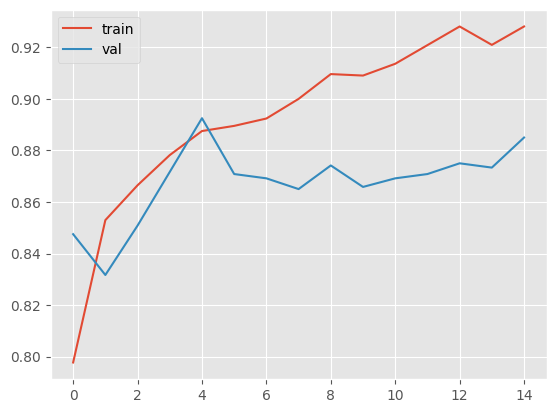

In [14]:
## Accuracy
plt.style.use("ggplot")
plt.plot(history.history['acc'])
plt.plot(history.history['val_acc'])
plt.legend(["train","val"],loc='upper left')

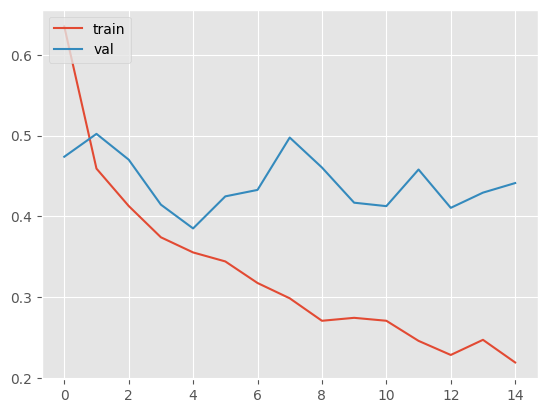

In [15]:
## Loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(["train", "val"],loc='upper left')

In [19]:
model.save("/kaggle/working/tf_model.hdf5")